# Phase 2 Deep Dive — Which Results Can We Trust?

**Status: analysis of Phase 2's final outputs (re-run 24 Oct 2026, after the v3 redesign, fusions
and the burden sensitivity flag); no pipeline changes.**

Phase 2 produced 1,824 significant gene pairs (of 6,697 tested) and 2,239 significant
mechanism-specific tests (of 8,445), 687 of them cross-mechanism (mutation in one gene, copy
number in the other). A significant q-value says "this pattern is not chance"; it does not say
"this pattern is a gene-gene interaction". Three other things can produce a real, reproducible
co-occurrence that has nothing to do with the two genes talking to each other:

1. **Histological subtype** -- both alterations define the same subtype, so
   they travel together (e.g. serous endometrial = *CCNE1* amp + *TP53* mut).
2. **Alteration burden** -- some tumours are simply unstable and carry more
   of everything; every amplification then "co-occurs" with every other.
   *TP53* loss is the classic driver of this.
3. **Physical proximity** -- the two genes sit on the same amplicon/deletion.

This notebook runs each of those checks across **every** significant
cross-mechanism hit (not spot checks), then adds one more that the pipeline
itself can't do: whether the OncoKB driver filter let through
tissue-specific passengers. It ends with the list of hits that survive
everything.

**Headline findings** (details below):
- Mutual **exclusivity** is more robust to subtype than co-occurrence: 80%
  vs 62% survive stratification, and only 1% of either direction reverses.
  Burden adjustment trims co-occurrence more than exclusivity (median 23% vs
  11.5% of the log odds ratio lost).
- ***TP53*-mutant tumours carry 2x more deep CNAs.** "X amplified co-occurs
  with *TP53* mutated" recurs across up to 8 cancer types (*MYC*, *ERBB2*) -- but
  that is one fact (p53 loss -> genomic instability), not 8 gene-specific
  interactions. Burden adjustment explains a median 26% of such hits and
  essentially all of four (*FGF3*/*FGF4* in bladder; *NKX2-1*, *TERT* in lung).
- Only 2.9% (20 of 687) of cross-mechanism hits are genomic neighbours (vs. a
  large share of CNV-CNV hits) -- the cross-mechanism design largely sidesteps
  the adjacency artifact.
- 16% (31 of 194) of subtype-robust co-occurrence hits involve a CNV gene that
  is an oncogene *somewhere* but a likely passenger *here* (*KIT*/*KDR* riding
  the *PDGFRA* amplicon in glioma; *FGF3*/*FGF4*/*FGF19* riding *CCND1*; *AURKA*
  riding *ZNF217*). The gene-level role filter is context-blind by construction.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
pd.set_option("future.no_silent_downcasting", True)

DATA = Path.cwd().parent / "data"
PROCESSED, RAW = DATA / "processed", DATA / "raw"

mech = pd.read_parquet(PROCESSED / "mechanism_pairs.parquet")
# Phase 2 now reports observed/expected (fold_enrichment) and its own direction call; the crude
# (pooled) odds ratio used by the checks below is rebuilt from the 2x2 counts (+0.5 against zero cells)
_a, _b, _c, _d = (mech[k] + 0.5 for k in ["n_both_altered", "n_A_only", "n_B_only", "n_neither"])
mech["odds_ratio"] = _a * _d / (_b * _c)
alterations = pd.read_parquet(PROCESSED / "alterations_long.parquet",
                              columns=["Sample_ID", "Hugo_Symbol", "Alteration_Type", "CANCER_TYPE", "CNA_TESTED"])
alterations = alterations[alterations["CNA_TESTED"]]
clinical = (pd.read_parquet(PROCESSED / "clinical_tidy.parquet",
                            columns=["SAMPLE_ID", "SEQ_ASSAY_ID", "CANCER_TYPE", "CANCER_TYPE_DETAILED", "CNA_TESTED"])
              .drop_duplicates("SAMPLE_ID"))
clinical = clinical[clinical["CNA_TESTED"]].set_index("SAMPLE_ID")
panel_coverage = pd.read_parquet(PROCESSED / "panel_gene_coverage.parquet", columns=["SEQ_ASSAY_ID", "Hugo_Symbol"])

sig = mech[mech["q_value"] < 0.05].copy()
cross = sig[sig["mech_A"] != sig["mech_B"]].copy()
# direction: taken from Phase 2 (conditional test), not from the crude odds ratio
print(f"crude odds ratio disagrees with Phase 2 direction in {int(((cross.odds_ratio > 1) != (cross.direction == 'co-occurring')).sum())} of {len(cross)} cross-mechanism hits")
print(f"significant mechanism tests: {len(sig):,} | cross-mechanism: {len(cross):,} "
      f"(co-occurring {int((cross.direction=='co-occurring').sum()):,}, exclusive {int((cross.direction=='exclusive').sum()):,})")

crude odds ratio disagrees with Phase 2 direction in 5 of 687 cross-mechanism hits
significant mechanism tests: 2,239 | cross-mechanism: 687 (co-occurring 313, exclusive 374)


## 1. Shared machinery

Everything below needs the same thing: for a (cancer type, gene A, mechanism,
gene B, mechanism) hit, the per-patient vectors "A altered this way" and "B
altered that way", restricted to CNA-tested patients whose panel covers both
genes. Built once per cancer type and reused.

The **Mantel-Haenszel common odds ratio** is the stratified estimate used
throughout: it combines the 2x2 tables from each stratum (subtype, or burden
band) into one odds ratio that is *not* driven by the strata's different
baseline rates. If the pooled OR is 5 and the MH OR is 1.2, the strata
explain most of the association.

In [2]:
def mh_odds_ratio(tables):
    # tables: list of (a, b, c, d) = (both, A-only, B-only, neither) per stratum
    num = sum(a * d / (a + b + c + d) for a, b, c, d in tables if a + b + c + d > 0)
    den = sum(b * c / (a + b + c + d) for a, b, c, d in tables if a + b + c + d > 0)
    return num / den if den > 0 else np.nan


def two_by_two(A, B):
    return (int((A & B).sum()), int((A & ~B).sum()), int((~A & B).sum()), int((~A & ~B).sum()))


def log_or_retained(pooled, adjusted):
    # 1 = adjustment changed nothing; 0 = association fully explained by strata; <0 = direction flipped
    lp, la = np.log(pooled), np.log(adjusted)
    return la / lp if np.isfinite(lp) and np.isfinite(la) and lp != 0 else np.nan


class CancerTypeContext:
    def __init__(self, cancer_type, genes):
        cs = clinical[clinical["CANCER_TYPE"] == cancer_type]
        self.samples = cs
        sub = alterations[(alterations["CANCER_TYPE"] == cancer_type)
                          & alterations["Hugo_Symbol"].isin(genes) & alterations["Sample_ID"].isin(cs.index)]
        def event_matrix(t):
            s = sub[sub["Alteration_Type"] == t][["Sample_ID", "Hugo_Symbol"]].drop_duplicates()
            return (s.assign(v=True).pivot(index="Sample_ID", columns="Hugo_Symbol", values="v")
                     .reindex(index=cs.index, columns=genes).fillna(False).astype(bool))
        self.M = {"SNV": event_matrix("MUT"), "CNV": event_matrix("CNV")}
        cov = (panel_coverage[panel_coverage["Hugo_Symbol"].isin(genes)].assign(c=True)
                 .pivot(index="SEQ_ASSAY_ID", columns="Hugo_Symbol", values="c").reindex(columns=genes).fillna(False))
        self.cov = cov.reindex(cs["SEQ_ASSAY_ID"]).fillna(False).astype(bool)
        self.cov.index = cs.index
        self.subtype = cs["CANCER_TYPE_DETAILED"].fillna("NA").to_numpy()
        cnv_all = alterations[(alterations["CANCER_TYPE"] == cancer_type) & (alterations["Alteration_Type"] == "CNV")]
        self.burden = cnv_all.groupby("Sample_ID").size().reindex(cs.index).fillna(0).astype(int).to_numpy()

    def vectors(self, gene_a, mech_a, gene_b, mech_b):
        el = (self.cov[gene_a] & self.cov[gene_b]).to_numpy()
        return el, self.M[mech_a][gene_a].to_numpy()[el], self.M[mech_b][gene_b].to_numpy()[el]


contexts = {}
def ctx_for(cancer_type, genes):
    key = cancer_type
    if key not in contexts:
        all_genes = sorted(set(sig.loc[sig["Cancer_Type"] == cancer_type, "Gene_A"])
                           | set(sig.loc[sig["Cancer_Type"] == cancer_type, "Gene_B"]))
        contexts[key] = CancerTypeContext(cancer_type, all_genes)
    return contexts[key]
print("ready")

ready


## 2. Check 1 -- histological subtype

Stratify each cross-mechanism hit by `CANCER_TYPE_DETAILED` and compare the
pooled odds ratio to the Mantel-Haenszel one. Also record the tell-tale
signature of confounding: one subtype supplying most of the co-occurring
patients while being a minority of all patients.

In [3]:
rows = []
for ct, grp in cross.groupby("Cancer_Type"):
    cx = ctx_for(ct, None)
    for r in grp.itertuples():
        el, A, B = cx.vectors(r.Gene_A, r.mech_A, r.Gene_B, r.mech_B)
        S = cx.subtype[el]
        tables, top = [], ("", 0, 0)
        for lev in np.unique(S):
            m = S == lev
            t = two_by_two(A[m], B[m]); tables.append(t)
            if t[0] > top[2]:
                top = (lev, int(m.sum()), t[0])
        mh = mh_odds_ratio(tables)
        n_both = int((A & B).sum())
        rows.append(dict(Cancer_Type=ct, Gene_A=r.Gene_A, mech_A=r.mech_A, Gene_B=r.Gene_B, mech_B=r.mech_B,
                         direction=r.direction, n_tested=int(el.sum()), n_both=n_both,
                         pooled_OR=r.odds_ratio, q_value=r.q_value, subtype_MH_OR=mh,
                         subtype_retained=log_or_retained(r.odds_ratio, mh),
                         top_subtype=str(top[0])[:40],
                         top_subtype_share_of_patients=top[1] / max(int(el.sum()), 1),
                         top_subtype_share_of_cooccur=top[2] / max(n_both, 1)))
checks = pd.DataFrame(rows)

def verdict(x):
    if not np.isfinite(x): return "undetermined"
    if x >= 0.75: return "robust"
    if x >= 0.40: return "attenuated"
    if x >= 0:    return "mostly_confounded"
    return "reversed"
checks["subtype_verdict"] = checks["subtype_retained"].map(verdict)

print("Share of hits by verdict:")
print(pd.crosstab(checks["direction"], checks["subtype_verdict"], normalize="index").round(2).to_string())
print("\nCounts:")
print(pd.crosstab(checks["direction"], checks["subtype_verdict"]).to_string())

/var/folders/pz/lfvpvb6d2wbdsny70113by7w0000gn/T/ipykernel_6944/981436814.py:14: RuntimeWarning: divide by zero encountered in log
  lp, la = np.log(pooled), np.log(adjusted)


/var/folders/pz/lfvpvb6d2wbdsny70113by7w0000gn/T/ipykernel_6944/981436814.py:14: RuntimeWarning: divide by zero encountered in log
  lp, la = np.log(pooled), np.log(adjusted)


/var/folders/pz/lfvpvb6d2wbdsny70113by7w0000gn/T/ipykernel_6944/981436814.py:14: RuntimeWarning: divide by zero encountered in log
  lp, la = np.log(pooled), np.log(adjusted)


/var/folders/pz/lfvpvb6d2wbdsny70113by7w0000gn/T/ipykernel_6944/981436814.py:14: RuntimeWarning: divide by zero encountered in log
  lp, la = np.log(pooled), np.log(adjusted)


Share of hits by verdict:
subtype_verdict  attenuated  mostly_confounded  reversed  robust  undetermined
direction                                                                     
co-occurring           0.27               0.10      0.01    0.62          0.00
exclusive              0.16               0.02      0.01    0.80          0.02

Counts:
subtype_verdict  attenuated  mostly_confounded  reversed  robust  undetermined
direction                                                                     
co-occurring             85                 30         2     195             1
exclusive                58                  8         4     298             6


/var/folders/pz/lfvpvb6d2wbdsny70113by7w0000gn/T/ipykernel_6944/981436814.py:14: RuntimeWarning: divide by zero encountered in log
  lp, la = np.log(pooled), np.log(adjusted)


**Exclusivity is the more robust signal.** 80% of exclusive hits survive
intact vs 62% of co-occurring ones (37% of co-occurring hits are attenuated,
mostly confounded or reversed, against 19% of exclusive ones). Reversal is rare
in both directions: 4 of 374 exclusive and 2 of 313 co-occurring hits.

The co-occurrence hits that collapse are largely the subtype-defining
combinations -- which is reassuring, because it means the check is catching
what it should:

In [4]:
cols = ["Cancer_Type", "Gene_A", "mech_A", "Gene_B", "mech_B", "n_both", "pooled_OR", "subtype_MH_OR",
        "top_subtype", "top_subtype_share_of_patients", "top_subtype_share_of_cooccur"]
bad = checks[(checks["direction"] == "co-occurring") & checks["subtype_verdict"].isin(["mostly_confounded", "reversed"])]
print(f"{len(bad)} co-occurring hits mostly explained by subtype. Largest pooled ORs:")
print(bad.nlargest(10, "pooled_OR")[cols].round(3).to_string(index=False))

32 co-occurring hits mostly explained by subtype. Largest pooled ORs:
               Cancer_Type Gene_A mech_A Gene_B mech_B  n_both  pooled_OR  subtype_MH_OR                              top_subtype  top_subtype_share_of_patients  top_subtype_share_of_cooccur
Non-Small Cell Lung Cancer  KMT2D    SNV PIK3CA    CNV      80      7.031          1.700             Lung Squamous Cell Carcinoma                          0.098                         0.862
       Soft Tissue Sarcoma CDKN2A    CNV    NF1    SNV      48      4.694          1.853                             Sarcoma, NOS                          0.154                         0.375
       Soft Tissue Sarcoma   ATRX    SNV   TP53    CNV      76      4.428          1.801 Undifferentiated Pleomorphic Sarcoma/Mal                          0.088                         0.316
       Soft Tissue Sarcoma    RB1    CNV   TP53    SNV     153      4.186          1.444                           Leiomyosarcoma                          0.135      

Reading the last two columns together is the whole story: in lung cancer,
squamous tumours are **9.8% of patients but supply 86% of the *KMT2D*-mut +
*PIK3CA*-amp co-occurrences** -- the pooled OR of 7.0 falls to 1.7 once subtype
is accounted for, so it was describing squamous-vs-adenocarcinoma, not a gene
interaction. Same pattern in sarcoma, where leiomyosarcoma is 13.5% of patients but
57.5% of the *RB1*-del + *TP53*-mut co-occurrences (OR 4.2 -> 1.4), and in glioma,
where glioblastoma supplies 75% of *MTAP*-del + *PTEN*-mut (OR 1.9 -> 1.1).

Exclusive hits that break are a smaller group (12) and spread over bladder,
mature B-cell lymphoma, lung, glioma and mature T/NK neoplasms. They move toward 1
rather than flipping (e.g. bladder *KDM6A* mut vs *RAF1* amp, OR 0.39 -> 0.74):

In [5]:
badx = checks[(checks["direction"] == "exclusive") & checks["subtype_verdict"].isin(["mostly_confounded", "reversed"])]
print(f"{len(badx)} exclusive hits mostly explained by subtype:")
print(badx.nsmallest(10, "pooled_OR")[["Cancer_Type", "Gene_A", "mech_A", "Gene_B", "mech_B", "n_both", "pooled_OR", "subtype_MH_OR", "top_subtype"]].round(3).to_string(index=False))

12 exclusive hits mostly explained by subtype:
               Cancer_Type Gene_A mech_A Gene_B mech_B  n_both  pooled_OR  subtype_MH_OR                              top_subtype
 Mature T and NK Neoplasms   TET2    SNV   TP53    CNV       4      0.060          0.580                        Mycosis Fungoides
            Bladder Cancer CREBBP    SNV   DDR2    CNV      13      0.070          0.433             Bladder Urothelial Carcinoma
                    Glioma CDKN2A    CNV    CIC    SNV      57      0.121          0.518                             Glioblastoma
            Bladder Cancer   MDM2    CNV  RBM10    SNV      22      0.165          0.623             Bladder Urothelial Carcinoma
Non-Small Cell Lung Cancer ARID1A    SNV  FOXA1    CNV      33      0.335          0.690                      Lung Adenocarcinoma
            Bladder Cancer  KDM6A    SNV   RAF1    CNV      51      0.386          0.737             Bladder Urothelial Carcinoma
            Bladder Cancer  KDM6A    SNV  P

Unlike the earlier run, none of these is the serous-vs-endometrioid split in
endometrial cancer (*CCNE1*/*ERBB2*/*FGFR1* amplification vs *PIK3CA*/*PIK3R1*/*PTEN*
mutation); that no longer appears among the confounded exclusive hits. What is
left is mostly modest attenuation, and the headline result stands: very few
exclusive hits are subtype artefacts.

## 3. Check 2 -- pan-cancer recurrence, and what it reveals

Phase 2's pan-cancer table works on the blended matrix. Doing the same on
mechanism-specific pairs (same pair, same mechanism combination, same
direction, >=3 cancer types) surfaces a pattern the blended version hides.

In [6]:
def norm_pair(r):
    return tuple(sorted([(r.Gene_A, r.mech_A), (r.Gene_B, r.mech_B)]))
cross["mpair"] = [norm_pair(r) for r in cross.itertuples()]
rec = (cross.groupby("mpair").agg(n_cancer_types=("Cancer_Type", "nunique"),
                                  directions=("direction", lambda s: set(s)),
                                  cancer_types=("Cancer_Type", lambda s: sorted(set(s))),
                                  median_OR=("odds_ratio", "median")).reset_index())
rec = rec[rec["directions"].map(len) == 1]
rec["direction"] = rec["directions"].map(lambda s: next(iter(s)))
rec["pair"] = rec["mpair"].map(lambda p: f"{p[0][0]}({p[0][1]}) x {p[1][0]}({p[1][1]})")
rec = rec[rec["n_cancer_types"] >= 3].sort_values("n_cancer_types", ascending=False)
rec["cancer_types_str"] = rec["cancer_types"].map(lambda c: ", ".join(x[:16] for x in c[:5]) + (" ..." if len(c) > 5 else ""))
print(f"{len(rec)} cross-mechanism pairs recur (consistent direction) in >= 3 cancer types\n")
print(rec[["pair", "direction", "n_cancer_types", "median_OR", "cancer_types_str"]].head(16).round(2).to_string(index=False))

14 cross-mechanism pairs recur (consistent direction) in >= 3 cancer types

                     pair    direction  n_cancer_types  median_OR                                                                        cancer_types_str
    MDM2(CNV) x TP53(SNV)    exclusive              10       0.07           Ampullary Cancer, Bladder Cancer, Breast Cancer, Esophagogastric , Glioma ...
CDKN2A(SNV) x CDKN2B(CNV)    exclusive               9       0.11        Bladder Cancer, Cancer of Unknow, Esophagogastric , Glioma, Head and Neck Ca ...
  CDKN2A(SNV) x MTAP(CNV)    exclusive               8       0.10        Bladder Cancer, Cancer of Unknow, Esophagogastric , Glioma, Hepatobiliary Ca ...
   ERBB2(CNV) x TP53(SNV) co-occurring               8       3.90 Bladder Cancer, Breast Cancer, Cancer of Unknow, Endometrial Canc, Esophagogastric  ...
     MYC(CNV) x TP53(SNV) co-occurring               8       3.09 Appendiceal Canc, Bladder Cancer, Breast Cancer, Cancer of Unknow, Colorectal Cance ...


Look at the top of that table: ***TP53*(SNV) co-occurs with copy-number gain of
*MYC* (8 cancer types) and *ERBB2* (8), with *RB1* loss (6), and with *PIK3CA*
and *PTEN* (3 each)** -- the same oncogenes, in many tissues.

That is not eight separate discoveries. It is one well-known fact: **p53
loss removes the checkpoint that stops chromosomally unstable cells from
dividing, so *TP53*-mutant tumours accumulate more copy-number changes of
everything.** The pipeline recovered a textbook principle of cancer biology
from the data -- good validation -- but it also means every "X amplified
co-occurs with *TP53* mutated" hit is partly a **burden** effect, the
copy-number analogue of the TMB problem for mutation pairs.

The exclusive recurrences are the clean ones: *MDM2*amp/*TP53*mut (10 cancer
types), *CDKN2A*(mut)/*CDKN2B*(CNV) (9) and *CDKN2A*(mut)/*MTAP*(CNV) (8) --
these two are neighbours on 9p21, see Check 4 -- *CDKN2A*del/*RB1*mut (6) and
*ERBB2*amp/*KRAS*mut (4): same-pathway redundancy or two routes to one locus,
all textbook.

## 4. Check 3 -- alteration burden

First, does the premise hold?

In [7]:
tp53_mut = set(alterations.loc[(alterations["Hugo_Symbol"] == "TP53") & (alterations["Alteration_Type"] == "MUT"), "Sample_ID"])
burden_all = alterations[alterations["Alteration_Type"] == "CNV"].groupby("Sample_ID").size()
b = clinical[["CANCER_TYPE"]].copy()
b["n_cna"] = burden_all.reindex(b.index).fillna(0).astype(int)
b["tp53_mut"] = b.index.isin(tp53_mut)

summary = (b.groupby("tp53_mut")["n_cna"].agg(mean="mean", share_with_any=lambda s: (s > 0).mean()))
print("All CNA-tested patients:"); print(summary.round(3).to_string())
print(f"\nTP53-mutant tumours carry {summary.loc[True,'mean']/summary.loc[False,'mean']:.2f}x more deep CNAs on average.\n")

per_ct = (b.groupby(["CANCER_TYPE", "tp53_mut"])["n_cna"].agg(lambda s: (s > 0).mean()).unstack()
            .rename(columns={False: "TP53wt", True: "TP53mut"}).dropna())
per_ct["n"] = b.groupby("CANCER_TYPE").size()
per_ct = per_ct[per_ct["n"] >= 2000].sort_values("TP53mut", ascending=False)
print("Share of patients with >= 1 deep CNA, cancer types with >= 2,000 CNA-tested patients:")
print(per_ct.round(3).to_string())

All CNA-tested patients:
           mean  share_with_any
tp53_mut                       
False     1.226           0.308
True      2.460           0.572

TP53-mutant tumours carry 2.01x more deep CNAs on average.

Share of patients with >= 1 deep CNA, cancer types with >= 2,000 CNA-tested patients:
tp53_mut                      TP53wt  TP53mut      n
CANCER_TYPE                                         
Breast Cancer                  0.589    0.761  16476
Esophagogastric Cancer         0.457    0.721   5255
Bladder Cancer                 0.580    0.687   5372
Ovarian Cancer                 0.303    0.647   5956
Cancer of Unknown Primary      0.409    0.611   4718
Soft Tissue Sarcoma            0.534    0.600   5664
Prostate Cancer                0.360    0.589   6742
Glioma                         0.620    0.573   7633
Hepatobiliary Cancer           0.370    0.573   3275
Endometrial Cancer             0.114    0.570   5776
Mature B-Cell Neoplasms        0.164    0.546  11026
Non-Small C

2x overall; in endometrial cancer **57% vs 11%**. Glioma is the one
exception (IDH-wildtype glioblastoma is CNV-heavy and *TP53*-poor; IDH-mutant
astrocytoma is the reverse) -- itself a known feature of glioma biology.

So: stratify the co-occurrence hits by the patient's count of *other* deep
CNAs (excluding the CNV gene under test, or we'd be conditioning on the
outcome). Bands: 0 / 1-2 / 3-5 / 6+.

In [8]:
def burden_check(cx, gene_a, mech_a, gene_b, mech_b, pooled):
    el, A, B = cx.vectors(gene_a, mech_a, gene_b, mech_b)
    cnv_gene = gene_a if mech_a == "CNV" else gene_b
    own = cx.M["CNV"][cnv_gene].to_numpy()[el].astype(int)
    other = cx.burden[el] - own
    bands = np.digitize(other, [1, 3, 6])
    tables = [two_by_two(A[bands == k], B[bands == k]) for k in range(4)]
    mh = mh_odds_ratio(tables)
    return mh, log_or_retained(pooled, mh)

bres = []
for r in checks.itertuples():
    cx = ctx_for(r.Cancer_Type, None)
    mh, ret = burden_check(cx, r.Gene_A, r.mech_A, r.Gene_B, r.mech_B, r.pooled_OR)
    bres.append((mh, ret))
checks["burden_MH_OR"] = [x[0] for x in bres]
checks["burden_retained"] = [x[1] for x in bres]
checks["burden_verdict"] = checks["burden_retained"].map(verdict)

print("Burden check, share of hits by verdict:")
print(pd.crosstab(checks["direction"], checks["burden_verdict"], normalize="index").round(2).to_string())
print("\nMedian share of log-OR retained after burden adjustment:")
print(checks.groupby("direction")["burden_retained"].median().round(3).to_string())

Burden check, share of hits by verdict:
burden_verdict  attenuated  mostly_confounded  reversed  robust  undetermined
direction                                                                    
co-occurring          0.37               0.08      0.00    0.54          0.00
exclusive             0.24               0.07      0.04    0.63          0.02

Median share of log-OR retained after burden adjustment:
direction
co-occurring    0.772
exclusive       0.885


/var/folders/pz/lfvpvb6d2wbdsny70113by7w0000gn/T/ipykernel_6944/981436814.py:14: RuntimeWarning: divide by zero encountered in log
  lp, la = np.log(pooled), np.log(adjusted)


In [9]:
tp53 = checks[(checks["direction"] == "co-occurring") & ((checks["Gene_A"] == "TP53") | (checks["Gene_B"] == "TP53"))]
other = checks[(checks["direction"] == "co-occurring") & ~((checks["Gene_A"] == "TP53") | (checks["Gene_B"] == "TP53"))]
print(f"Co-occurring hits involving TP53: {len(tp53)} | median retained after burden adj = {tp53['burden_retained'].median():.2f}")
print(f"Co-occurring hits NOT involving TP53: {len(other)} | median retained = {other['burden_retained'].median():.2f}")
print("\nTP53 partners fully explained by burden (retained <= 0.2):")
gone = tp53[tp53["burden_retained"] <= 0.2]
print(gone[["Cancer_Type", "Gene_A", "mech_A", "Gene_B", "mech_B", "n_both", "pooled_OR", "burden_MH_OR", "burden_retained"]].round(3).to_string(index=False))

Co-occurring hits involving TP53: 83 | median retained after burden adj = 0.74
Co-occurring hits NOT involving TP53: 230 | median retained = 0.79

TP53 partners fully explained by burden (retained <= 0.2):
               Cancer_Type Gene_A mech_A Gene_B mech_B  n_both  pooled_OR  burden_MH_OR  burden_retained
            Bladder Cancer   FGF3    CNV   TP53    SNV     234      1.563         1.048            0.104
            Bladder Cancer   FGF4    CNV   TP53    SNV     244      1.528         1.013            0.031
Non-Small Cell Lung Cancer NKX2-1    CNV   TP53    SNV     860      1.628         1.050            0.100
Non-Small Cell Lung Cancer   TERT    CNV   TP53    SNV     682      1.489         1.028            0.070


Burden adjustment trims co-occurrence by about 23% at the median (median share of
log odds ratio retained 0.77) and exclusivity by about 11.5% (0.885), and wipes
out some co-occurrence hits entirely: *FGF3*/*FGF4* amplification with *TP53*
mutation in bladder cancer (pooled OR 1.5 -> 1.0) and *NKX2-1*/*TERT*
amplification with *TP53* mutation in lung cancer (1.5-1.6 -> 1.0) were pure
instability. *TP53* partners are hit harder than other co-occurring hits (median
retained 0.74 vs 0.79), as the burden story predicts, but the gap is modest.

Exclusivity is *not* immune here, unlike with subtype: 63% of exclusive hits are
robust, 24% attenuated, 7% mostly confounded and 4% reversed. A likely reason is
that burden is partly a **consequence** of the same biology being tested: *TP53*
loss *causes* instability, so stratifying on instability partly strips out the
*TP53* effect itself (adjusting for a mediator). That is a hypothesis, not tested
here. The strongest exclusive hits stay strong: *MDM2*/*TP53* strengthens
(0.066 -> 0.038 in bladder, 0.065 -> 0.044 in oesophagogastric), *EGFR*/*IDH1* weakens
slightly but stays well below 0.1 (0.034 -> 0.053). So: treat burden-adjusted ORs
as a **conservative bound**, not as the truth, and report both.

Phase 2 now carries this as a column: `burden_robust` is reported next to every pair
(1,276 of the 1,584 interaction candidates pass), as a flag rather than a default,
because building burden into the main test over-adjusts (it loses the known
*CCND1*/*FGFR1* co-amplification). The permutation-style, load-preserving test that an
earlier version of this notebook recommended is already the main test (the
conditional test); notebook 02b shows it is the only method that stays calibrated.

## 5. Check 4 -- physical proximity

The blended CNV-CNV tests are dominated by neighbours on the same amplicon
(*CDKN2A*/*CDKN2B*, crude odds ratio above 9,900 in several cancer types). Do cross-mechanism
hits have the same problem?

In [10]:
g = pd.read_csv(RAW / "genomic_information.txt", sep="\t",
                usecols=["Hugo_Symbol", "Chromosome", "Start_Position", "End_Position"], low_memory=False)
g = g.groupby("Hugo_Symbol").agg(chrom=("Chromosome", "first"), start=("Start_Position", "min"), end=("End_Position", "max"))
g = g[(g["end"] - g["start"]) <= 3_000_000]         # same corrupted-coordinate guard as Phase 2

def distance_bp(a, b):
    if a not in g.index or b not in g.index: return np.nan
    ra, rb = g.loc[a], g.loc[b]
    if str(ra["chrom"]) != str(rb["chrom"]): return np.inf
    return max(0, max(ra["start"], rb["start"]) - min(ra["end"], rb["end"]))

checks["distance_bp"] = [distance_bp(a, b) for a, b in zip(checks["Gene_A"], checks["Gene_B"])]
checks["neighbours"] = checks["distance_bp"] <= 3_000_000
print(f"cross-mechanism hits on the same chromosome within 3 Mb: {int(checks['neighbours'].sum())} of {len(checks)} "
      f"({checks['neighbours'].mean():.1%}); on different chromosomes: {int((checks['distance_bp']==np.inf).sum())}")
nb = checks[checks["neighbours"]].copy(); nb["kb_apart"] = (nb["distance_bp"] / 1000).round()
print("\nThe neighbours:")
print(nb.sort_values("distance_bp")[["Cancer_Type", "Gene_A", "mech_A", "Gene_B", "mech_B", "n_both", "pooled_OR", "kb_apart"]].round(2).to_string(index=False))

cross-mechanism hits on the same chromosome within 3 Mb: 20 of 687 (2.9%); on different chromosomes: 633

The neighbours:
               Cancer_Type Gene_A mech_A Gene_B mech_B  n_both  pooled_OR  kb_apart
            Bladder Cancer CDKN2A    SNV CDKN2B    CNV      11       0.11       8.0
 Cancer of Unknown Primary CDKN2A    SNV CDKN2B    CNV       5       0.10       8.0
Non-Small Cell Lung Cancer CDKN2A    SNV CDKN2B    CNV      20       0.11       8.0
    Esophagogastric Cancer CDKN2A    SNV CDKN2B    CNV      10       0.15       8.0
                    Glioma CDKN2A    SNV CDKN2B    CNV      20       0.20       8.0
                  Melanoma CDKN2A    SNV CDKN2B    CNV      15       0.19       8.0
         Pancreatic Cancer CDKN2A    SNV CDKN2B    CNV       7       0.02       8.0
      Head and Neck Cancer CDKN2A    SNV CDKN2B    CNV       2       0.02       8.0
      Hepatobiliary Cancer CDKN2A    SNV CDKN2B    CNV       0       0.03       8.0
Non-Small Cell Lung Cancer CDKN2A    S

**2.9%.** The cross-mechanism design largely sidesteps the adjacency
artifact, because a mutation in A and an amplification of a neighbour B are
not the same physical event. The 20 that remain are biologically readable:
*CDKN2A*(SNV) vs *CDKN2B*(CNV) (9 hits, 8 kb apart) and vs *MTAP*(CNV) (8 hits, 30 kb)
are all *exclusive* = two ways to kill one locus; *KIT*/*KDR*(CNV) with
*PDGFRA*(SNV) in glioma and *KDR*(CNV) with *KIT*(SNV) in melanoma = the 4q12
amplicon, where *PDGFRA* is the driver and the others ride along.

## 6. Check 5 -- is the CNV gene a passenger *here*?

The OncoKB direction filter asks "is amplification consistent with this
gene's role?" -- at the gene level, with no tissue context. *KIT* is an
oncogene (in GIST and melanoma), so *KIT* amplification passes. In glioma,
*KIT* amplification is the *PDGFRA* amplicon: same 4q12 event, *PDGFRA* is
what matters, *KIT* is luggage.

Heuristic: flag robust co-occurrence hits whose CNV gene sits within 3 Mb of
a well-known amplicon driver.

In [11]:
KNOWN_AMPLICON_DRIVERS = {"ERBB2", "CCND1", "MYC", "FGFR1", "EGFR", "MDM2", "CDK4", "CCNE1",
                          "PDGFRA", "KRAS", "MET", "AKT2", "ZNF217", "RPS6KB1", "PPM1D", "MYCN", "MYCL"}
def near_known_driver(gene):
    return ",".join(sorted(d for d in KNOWN_AMPLICON_DRIVERS if d != gene and distance_bp(gene, d) <= 3_000_000))

checks["cnv_gene"] = np.where(checks["mech_A"] == "CNV", checks["Gene_A"], checks["Gene_B"])
checks["snv_gene"] = np.where(checks["mech_A"] == "SNV", checks["Gene_A"], checks["Gene_B"])
checks["cnv_gene_near_known_driver"] = checks["cnv_gene"].map(near_known_driver)

robust_co = checks[(checks["direction"] == "co-occurring") & (checks["subtype_verdict"] == "robust") & (checks["n_both"] >= 20)]
flagged = robust_co[robust_co["cnv_gene_near_known_driver"] != ""]
print(f"{len(flagged)} of {len(robust_co)} subtype-robust co-occurrence hits (n_both >= 20) have a CNV gene "
      f"within 3 Mb of a famous amplicon driver ({len(flagged)/len(robust_co):.0%}):")
print(flagged.sort_values("pooled_OR", ascending=False)[
    ["Cancer_Type", "cnv_gene", "snv_gene", "n_both", "pooled_OR", "subtype_MH_OR", "cnv_gene_near_known_driver"]].round(2).to_string(index=False))

31 of 194 subtype-robust co-occurrence hits (n_both >= 20) have a CNV gene within 3 Mb of a famous amplicon driver (16%):
         Cancer_Type cnv_gene snv_gene  n_both  pooled_OR  subtype_MH_OR cnv_gene_near_known_driver
            Melanoma      KDR      KIT      32      14.63           8.14                     PDGFRA
              Glioma      KIT   PDGFRA      95      13.53           9.40                     PDGFRA
              Glioma      KDR   PDGFRA      70      12.68           8.56                     PDGFRA
Head and Neck Cancer    FGF19     TP53     144      10.23           6.84                      CCND1
Head and Neck Cancer     FGF4     TP53     137       8.93           6.33                      CCND1
       Breast Cancer    PPM1D    GATA3     422       8.85           7.79                    RPS6KB1
Head and Neck Cancer     FGF3     TP53     143       8.43           5.93                      CCND1
      Bladder Cancer  WHSC1L1     TP53     106       4.66           3.76      

*KIT*/*KDR* in glioma and melanoma (-> *PDGFRA*, 4q12), *FGF3*/*FGF4*/*FGF19* in head and
neck, breast and bladder (-> *CCND1*, 11q13), *AURKA* in breast and colorectal
(-> *ZNF217*, 20q13), *WHSC1L1* in bladder and breast (-> *FGFR1*, 8p11), *PPM1D* in breast
(-> *RPS6KB1*, 17q23). All plausible passengers of a famous neighbour; all passed
the driver filter because the gene is a genuine oncogene in some other tissue. This is
a structural limit of gene-level role annotation and worth a sentence in the write-up.

**And the heuristic itself has a hole:** *CD79B*(CNV) x *GATA3*(SNV) in
breast cancer (n=340, OR=9.3) survives into the safe list below, but *CD79B*
is a B-cell lymphoma gene with no role in breast cancer -- it sits on the
17q23 amplicon, **3.26 Mb** from *PPM1D*, just past the 3 Mb cutoff. It is
almost certainly a passenger of the luminal 17q23 gain. Left in rather than
tuning the threshold to make it vanish; it is the clearest argument that a
tissue-aware driver list is the real fix, not a distance rule.

## 7. What survives everything

A cross-mechanism hit goes on the "safe to present" list if it is robust to
subtype **and** burden, is not a genomic neighbour, has a CNV gene not
obviously riding a famous amplicon, and rests on at least 20 co-occurring
(or, for exclusivity, at least 20 expected) patients.

In [12]:
safe = checks[
    checks["subtype_verdict"].eq("robust") & checks["burden_verdict"].eq("robust")
    & ~checks["neighbours"] & checks["cnv_gene_near_known_driver"].eq("")
].copy()
safe_co = safe[(safe["direction"] == "co-occurring") & (safe["n_both"] >= 20)]
safe_ex = safe[safe["direction"] == "exclusive"]
# for exclusivity, require the pair to be common enough that >= 20 co-occurrences were EXPECTED
safe_ex = safe_ex[(safe_ex["n_both"] / np.maximum(safe_ex["pooled_OR"], 1e-9)) >= 20]

print(f"cross-mechanism hits: {len(checks):,} -> survive all checks: {len(safe_co) + len(safe_ex):,} "
      f"(co-occurring {len(safe_co)}, exclusive {len(safe_ex)})\n")
show = ["Cancer_Type", "Gene_A", "mech_A", "Gene_B", "mech_B", "n_both", "pooled_OR", "subtype_MH_OR", "burden_MH_OR", "q_value"]
print("STRONGEST SURVIVING EXCLUSIVITY:")
print(safe_ex.nsmallest(15, "pooled_OR")[show].round(3).to_string(index=False))
print("\nSTRONGEST SURVIVING CO-OCCURRENCE:")
print(safe_co.nlargest(15, "pooled_OR")[show].round(3).to_string(index=False))

checks.to_parquet(PROCESSED / "mechanism_pairs_checked.parquet", index=False)
print(f"\nwrote mechanism_pairs_checked.parquet ({len(checks):,} rows, every cross-mechanism hit with all four checks)")

cross-mechanism hits: 687 -> survive all checks: 260 (co-occurring 107, exclusive 153)

STRONGEST SURVIVING EXCLUSIVITY:
           Cancer_Type Gene_A mech_A Gene_B mech_B  n_both  pooled_OR  subtype_MH_OR  burden_MH_OR  q_value
                Glioma   IDH1    SNV   MDM4    CNV       1      0.019          0.026         0.020    0.000
   Soft Tissue Sarcoma   CDK4    CNV    RB1    SNV       1      0.029          0.060         0.015    0.001
    Endometrial Cancer CTNNB1    SNV  ERBB2    CNV       1      0.029          0.043         0.026    0.003
              Melanoma   BRAF    SNV   NRAS    CNV       2      0.030          0.055         0.070    0.000
        Bladder Cancer   HRAS    SNV   MDM2    CNV       1      0.032          0.047         0.054    0.000
                Glioma   EGFR    CNV   IDH1    SNV      26      0.034          0.070         0.053    0.000
      Ampullary Cancer   MDM2    CNV   TP53    SNV       2      0.037          0.050         0.057    0.000
               

## 8. Visualise

/Users/user/Downloads/fyp/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


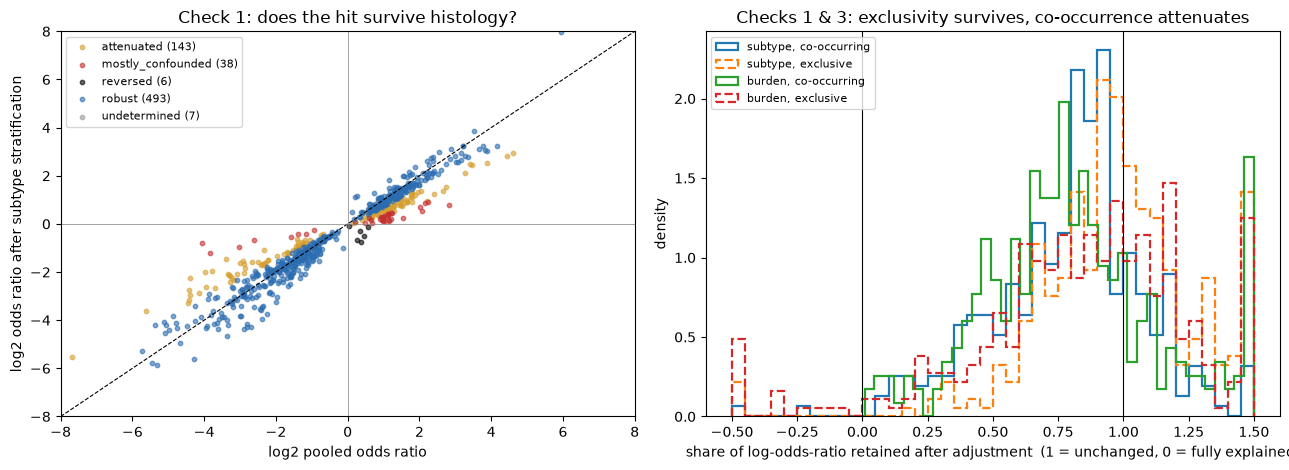

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# left: pooled vs subtype-adjusted OR, coloured by verdict
ax = axes[0]
pal = {"robust": "#2b6cb0", "attenuated": "#d69e2e", "mostly_confounded": "#c53030", "reversed": "#000000", "undetermined": "#999999"}
for v, grp in checks.groupby("subtype_verdict"):
    ax.scatter(np.log2(grp["pooled_OR"]), np.log2(grp["subtype_MH_OR"]), s=10, alpha=0.6, label=f"{v} ({len(grp)})", c=pal[v])
lim = 8; ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8); ax.axhline(0, c="grey", lw=0.5); ax.axvline(0, c="grey", lw=0.5)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("log2 pooled odds ratio"); ax.set_ylabel("log2 odds ratio after subtype stratification")
ax.set_title("Check 1: does the hit survive histology?"); ax.legend(fontsize=8, loc="upper left")

# right: retained fraction distributions
ax = axes[1]
for lbl, col in [("subtype", "subtype_retained"), ("burden", "burden_retained")]:
    for d, ls in [("co-occurring", "-"), ("exclusive", "--")]:
        v = checks.loc[checks["direction"] == d, col].dropna().clip(-0.5, 1.5)
        ax.hist(v, bins=40, histtype="step", lw=1.6, ls=ls, label=f"{lbl}, {d}", density=True)
ax.axvline(1, c="k", lw=0.8); ax.axvline(0, c="k", lw=0.8)
ax.set_xlabel("share of log-odds-ratio retained after adjustment  (1 = unchanged, 0 = fully explained)")
ax.set_ylabel("density"); ax.set_title("Checks 1 & 3: exclusivity survives, co-occurrence attenuates")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Discussion

**What this changes about how to read Phase 2.** A significant q-value is
the entry ticket, not the conclusion. Roughly a third of cross-mechanism
co-occurrence hits (37%) are partly or wholly explained by histological subtype,
most are trimmed by alteration burden (median 23%), and a sizeable minority of the
survivors involve a copy-number gene that is a passenger in that tissue (16% of the
subtype-robust ones). **Mutual exclusivity is the more trustworthy result type** --
robust to subtype (80%), rarely reversing (1%), and its strongest members
(*MDM2*/*TP53*) stay strong under every adjustment -- though it is not immune to
the burden check, for a reason that is itself informative (burden is partly
caused by the genes being tested).

**The most useful single finding** is the *TP53*-burden effect. That "X
amplified co-occurs with *TP53* mutated" recurs across up to 8 cancer types is
the pipeline rediscovering that p53 loss causes chromosomal instability. It
is worth presenting *as that* -- one principle, recovered blind -- rather
than as separate pair-level results.

**The safe list** (Section 7) is what to show Jason -- 260 of 687 hits (107
co-occurring, 153 exclusive). Exclusivity: *MDM2*amp/*TP53*mut (8 cancer types,
including bladder, sarcoma, oesophagogastric, glioma), *EGFR*amp/*IDH1*mut in glioma,
*EGFR*amp/*KRAS*mut and *MET*amp/*KRAS*mut in lung, *CDKN2A*del/*RB1*mut (6 types).
Co-occurrence: *ATRX*del/*IDH1*mut in glioma (stronger under every adjustment:
OR 62 -> 249 -> 280), *CCNE1*amp/*TP53*mut in cancer of unknown primary, *ERBB2*amp/*TP53*mut
in endometrial and hepatobiliary cancer, *CCND1*amp/*TP53*mut in head and neck. Read the
co-occurrence side with the *CD79B* caveat in mind: "survived every check" still isn't
"is a gene interaction".

**Status of the recommendations from the earlier version of this notebook:**
1. Report burden-adjusted odds ratios alongside pooled ones -- **done**:
   Phase 2 carries `burden_robust`, and `mechanism_pairs_checked.parquet` has the
   adjusted ORs for every cross-mechanism hit.
2. Replace Fisher's exact test with a load-preserving test -- **done**: the main test
   is the conditional (Rasch) test; notebook 02b benchmarks it against Fisher and a
   DISCOVER-style test.
3. Fit subtype-specific rates for all significant pairs -- **done** in Phase 2 proper
   (gene rates fitted within detailed subtypes); the stratified odds ratios here remain
   an extra, interpretable check on the cross-mechanism hits.
4. **Still open:** a tissue-aware driver list would fix the *KIT*-in-glioma class of
   passenger; the 3 Mb-from-a-known-driver heuristic here is a stopgap.

**Not done here:** the same-mechanism hits (SNV-SNV and CNV-CNV) got none of
these checks and will need them -- SNV-SNV co-occurrence is exposed to the
TMB analogue of the burden effect, and CNV-CNV to adjacency far more than
the 2.9% seen here.